In [1]:
import numpy as np 
import pandas as pd


df = pd.read_csv('Churn_Modelling.csv')
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [2]:
df.drop(
    columns=['RowNumber', 'CustomerId', 'Surname'],
    inplace=True,
    errors='ignore'
)

In [3]:
print(df.columns.tolist())


NameError: name 'df' is not defined

In [1]:
# Encode categorical columns
df = pd.get_dummies(df, columns=['Geography', 'Gender'], dtype=int)

NameError: name 'pd' is not defined

In [2]:
df

NameError: name 'df' is not defined

In [44]:
X = df.drop(columns=['Exited'])
y = df['Exited']

# Split the dataset
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape)

(8000, 13)


In [8]:
# Scale the features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_trf = scaler.fit_transform(X_train) #learns the scaling statistics and scales the training data
X_test_trf = scaler.transform(X_test)  #scales the test data using the training statistics

In [16]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input


In [23]:
model=Sequential()
model.add(Input(shape=(13,)))

model.add(Dense(11,activation='sigmoid'))
model.add(Dense(1,activation='sigmoid'))

In [18]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                      │ (None, 11)                  │             132 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 1)                   │              12 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 144 (576.00 B)

 Trainable params: 144 (576.00 B)

 Non-trainable params: 0 (0.00 B)

In [24]:
model.compile(optimizer='Adam',loss='binary_crossentropy',metrics=['accuracy']) #compiling tells Keras how to train the model

In [45]:
history = model.fit(X_train_trf,y_train,batch_size=50,epochs=10,verbose=1,validation_split=0.2)

Epoch 1/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7931 - loss: 0.4748 - val_accuracy: 0.8075 - val_loss: 0.4341
Epoch 2/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8037 - loss: 0.4390 - val_accuracy: 0.8206 - val_loss: 0.4203
Epoch 3/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8112 - loss: 0.4308 - val_accuracy: 0.8244 - val_loss: 0.4154
Epoch 4/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8148 - loss: 0.4272 - val_accuracy: 0.8263 - val_loss: 0.4124
Epoch 5/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8167 - loss: 0.4248 - val_accuracy: 0.8269 - val_loss: 0.4105
Epoch 6/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8194 - loss: 0.4229 - val_accuracy: 0.8269 - val_loss: 0.4089
Epoch 7/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8202 - loss: 0.4212 - val_accuracy: 0.8281 - val_loss: 0.4074
Epoch 8/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8208 - loss: 0.4195 - val_accuracy: 0.

In [53]:
y_prob = model.predict(X_test_trf)


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [54]:


y_pred = (y_prob >= 0.5).astype(int).ravel()

In [57]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)
print("Test Accuracy:", accuracy)

Test Accuracy: 0.8235


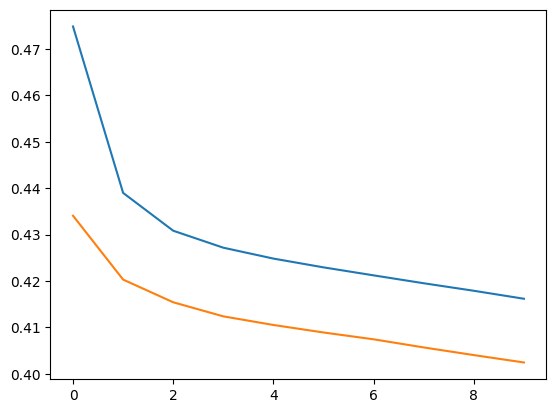

In [58]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

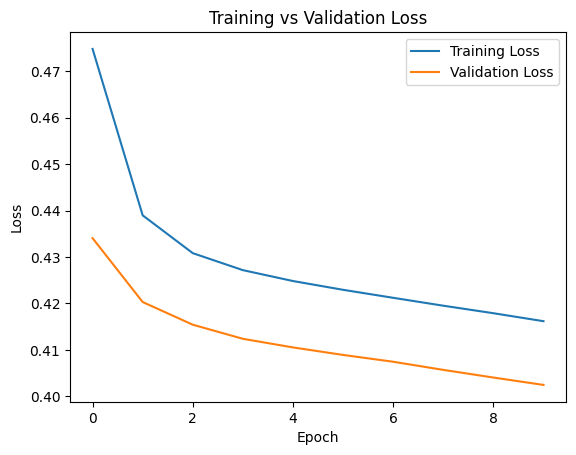

In [59]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.show()